# 01 · EDA · «BiciPrevisión» · equipo «Las Palmeras» (entrega de referencia, Sprint 14)

**Pregunta de negocio:** *¿podemos prever cuántas bicis se alquilarán en cada hora de mañana para que el operador decida cuántas recolocar en cada turno?*

**Datos:** `bicis_horas.csv`, el sistema de bicis compartidas de Washington D. C. de 2011 y 2012 (UCI Bike Sharing, **CC BY 4.0**, tal cual). Una fila por hora con alquileres, calendario y clima.

**Qué hace este cuaderno:** describe los datos, busca nulos, duplicados, horas que faltan y valores raros, mira **quién o qué falta** (sesgo de muestreo) y posibles **fugas**, enseña cuatro gráficos que responden a la pregunta y cierra con el informe de calidad y el linaje. Termina con un hallazgo que **cambia el enfoque**.

**Cómo se ejecuta:** *Entorno de ejecución → Reiniciar y ejecutar todo* (segundos). `SEMILLA = 42`. Si no hay carpeta `datos/`, la primera celda descarga el CSV.

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


## 1. Describir los datos

In [2]:
horas = pd.read_csv(dato("bicis_horas.csv"), parse_dates=["dteday"])
print("Filas y columnas:", horas.shape)
print("Periodo:", horas["dteday"].min().date(), "→", horas["dteday"].max().date(), f"({horas['dteday'].nunique()} días)")
print(horas.dtypes.to_string())
horas.head(3)

Filas y columnas: (17379, 17)
Periodo: 2011-01-01 → 2012-12-31 (731 días)
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32


## 2. Calidad: nulos, duplicados, horas que faltan y valores raros

In [3]:
# Calidad: nulos, duplicados, horas que faltan, valores raros y comprobaciones de coherencia
horas["ts"] = horas["dteday"] + pd.to_timedelta(horas["hr"], unit="h")
esperadas = pd.date_range(horas["ts"].min(), horas["ts"].max(), freq="h")
n_nulos = int(horas.isna().sum().sum())
n_duplicados = int(horas.duplicated().sum())
n_ts_repetidos = int(horas["ts"].duplicated().sum())
n_faltan = len(esperadas) - horas["ts"].nunique()
print("Nulos en todo el fichero:", n_nulos, "· filas duplicadas:", n_duplicados, "· horas repetidas:", n_ts_repetidos)
print(f"Horas esperadas: {len(esperadas)} · horas presentes: {horas['ts'].nunique()} · faltan: {n_faltan}")
huecos = pd.Series(esperadas.difference(horas["ts"]))
print("Las horas que faltan son horas de madrugada (alquileres = 0):", huecos.dt.hour.value_counts().sort_index().head(8).to_dict())

coherente = bool((horas["cnt"] == horas["casual"] + horas["registered"]).all())
print("cnt = casual + registered en todas las filas:", coherente)
n_hum0 = int((horas["hum"] == 0).sum()); n_viento0 = int((horas["windspeed"] == 0).sum())
dias_hum0 = horas.loc[horas["hum"] == 0, "dteday"].dt.date.unique().tolist()
print(f"Humedad = 0 en {n_hum0} filas (días {dias_hum0}) · viento = 0 en {n_viento0} filas ({n_viento0 / len(horas):.1%})")
print("Valores de weathersit:", horas["weathersit"].value_counts().sort_index().to_dict(), "(el 4 = tormenta casi no aparece)")
print(horas[["cnt", "temp", "hum", "windspeed"]].describe().round(2).T.to_string())

Nulos en todo el fichero: 0 · filas duplicadas: 0 · horas repetidas: 0
Horas esperadas: 17544 · horas presentes: 17379 · faltan: 165
Las horas que faltan son horas de madrugada (alquileres = 0): {0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4}
cnt = casual + registered en todas las filas: True
Humedad = 0 en 22 filas (días [datetime.date(2011, 3, 10)]) · viento = 0 en 2180 filas (12.5%)
Valores de weathersit: {1: 11413, 2: 4544, 3: 1419, 4: 3} (el 4 = tormenta casi no aparece)
             count    mean     std   min    25%     50%     75%     max
cnt        17379.0  189.46  181.39  1.00  40.00  142.00  281.00  977.00
temp       17379.0    0.50    0.19  0.02   0.34    0.50    0.66    1.00
hum        17379.0    0.63    0.19  0.00   0.48    0.63    0.78    1.00
windspeed  17379.0    0.19    0.12  0.00   0.10    0.19    0.25    0.85


## 3. Cuatro gráficos que responden a la pregunta

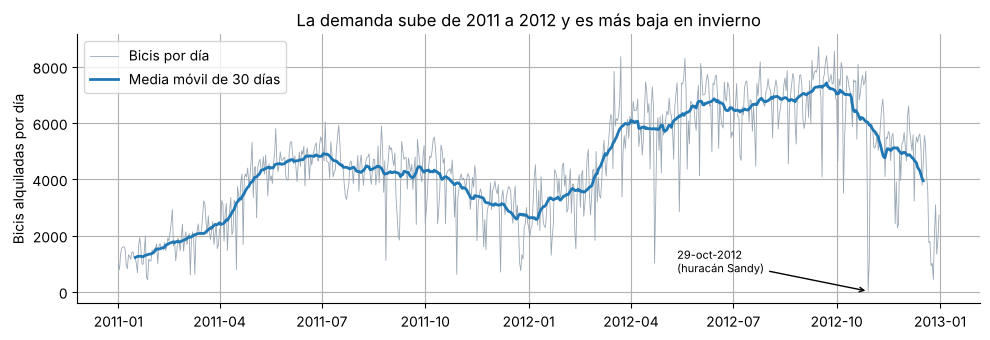

Media diaria: 2011 = 3406 · 2012 = 5600 · crecimiento = 64%
El 29-oct-2012 solo hubo 22 alquileres (media de ese año: 5600)


In [4]:
# Gráfico 1 · La serie: ¿hay tendencia y estaciones?
por_dia = horas.groupby("dteday")["cnt"].sum()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(por_dia.index, por_dia.values, lw=0.6, color="#9aa7b4", label="Bicis por día")
ax.plot(por_dia.index, por_dia.rolling(30, center=True).mean(), lw=2, color="#1f77b4", label="Media móvil de 30 días")
dia_sandy = pd.Timestamp("2012-10-29")
ax.annotate("29-oct-2012\n(huracán Sandy)", (dia_sandy, por_dia[dia_sandy]), xytext=(dia_sandy - pd.Timedelta(days=170), 700), arrowprops=dict(arrowstyle="->"), fontsize=8)
ax.set_title("La demanda sube de 2011 a 2012 y es más baja en invierno"); ax.set_ylabel("Bicis alquiladas por día"); ax.legend()
plt.tight_layout(); plt.show()
media_dia = por_dia.groupby(por_dia.index.year).mean()
crecimiento = float(media_dia[2012] / media_dia[2011] - 1)
print(f"Media diaria: 2011 = {media_dia[2011]:.0f} · 2012 = {media_dia[2012]:.0f} · crecimiento = {crecimiento:.0%}")
print(f"El 29-oct-2012 solo hubo {por_dia[dia_sandy]:.0f} alquileres (media de ese año: {media_dia[2012]:.0f})")

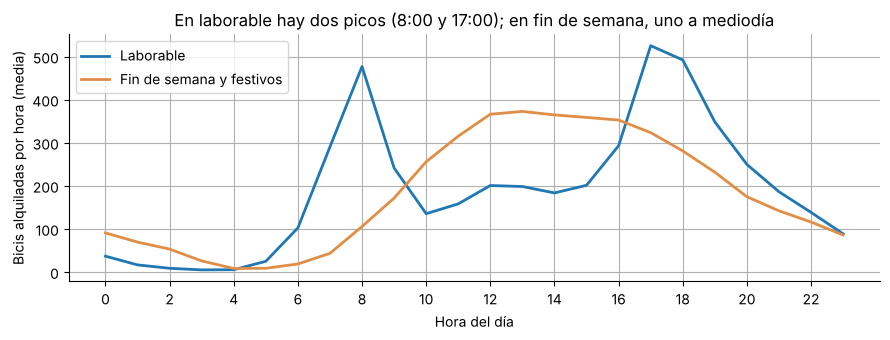

Hora del pico: laborable 17:00 (525 bicis/h) · fin de semana 13:00 (373 bicis/h)


In [5]:
# Gráfico 2 · El día tiene dos formas distintas: laborable y fin de semana
perfil = horas.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
perfil.columns = ["Fin de semana y festivos", "Laborable"]
fig, ax = plt.subplots(figsize=(9, 3.5))
perfil["Laborable"].plot(ax=ax, color="#1f77b4", lw=2); perfil["Fin de semana y festivos"].plot(ax=ax, color="#e08e45", lw=2)
ax.set_title("En laborable hay dos picos (8:00 y 17:00); en fin de semana, uno a mediodía")
ax.set_xlabel("Hora del día"); ax.set_ylabel("Bicis alquiladas por hora (media)"); ax.set_xticks(range(0, 24, 2)); ax.legend()
plt.tight_layout(); plt.show()
pico_lab = int(perfil["Laborable"].idxmax()); pico_fin = int(perfil["Fin de semana y festivos"].idxmax())
print(f"Hora del pico: laborable {pico_lab}:00 ({perfil['Laborable'].max():.0f} bicis/h) · fin de semana {pico_fin}:00 ({perfil['Fin de semana y festivos'].max():.0f} bicis/h)")

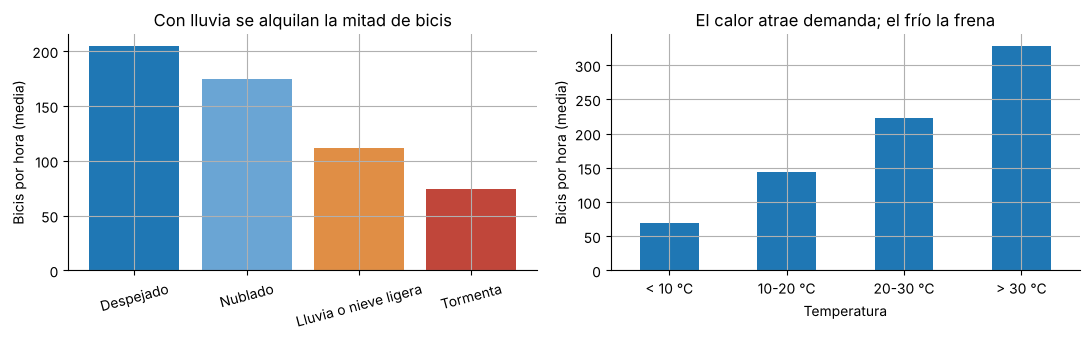

             mean   size
weathersit              
1           205.0  11413
2           175.0   4544
3           112.0   1419
4            74.0      3
Con lluvia o nieve ligera la demanda cae un 45% frente a un día despejado; solo hay 3 horas de tormenta


In [6]:
# Gráfico 3 · El clima (subgrupos): ¿cuánto cambia la demanda con la lluvia y el frío?
por_clima = horas.groupby("weathersit")["cnt"].agg(["mean", "size"]).round(0)
etiquetas = {1: "Despejado", 2: "Nublado", 3: "Lluvia o nieve ligera", 4: "Tormenta"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].bar([etiquetas[i] for i in por_clima.index], por_clima["mean"], color=["#1f77b4", "#6aa5d4", "#e08e45", "#c0463a"])
ejes[0].set_title("Con lluvia se alquilan la mitad de bicis"); ejes[0].set_ylabel("Bicis por hora (media)"); ejes[0].tick_params(axis="x", labelrotation=15)
tramos = pd.cut(horas["temp"] * 41, bins=[0, 10, 20, 30, 41], labels=["< 10 °C", "10-20 °C", "20-30 °C", "> 30 °C"])
horas.groupby(tramos, observed=True)["cnt"].mean().plot.bar(ax=ejes[1], color="#1f77b4", rot=0)
ejes[1].set_title("El calor atrae demanda; el frío la frena"); ejes[1].set_xlabel("Temperatura"); ejes[1].set_ylabel("Bicis por hora (media)")
plt.tight_layout(); plt.show()
cae_lluvia = float(1 - por_clima.loc[3, "mean"] / por_clima.loc[1, "mean"])
print(por_clima.to_string())
print(f"Con lluvia o nieve ligera la demanda cae un {cae_lluvia:.0%} frente a un día despejado; solo hay {int(por_clima.loc[4, 'size'])} horas de tormenta")

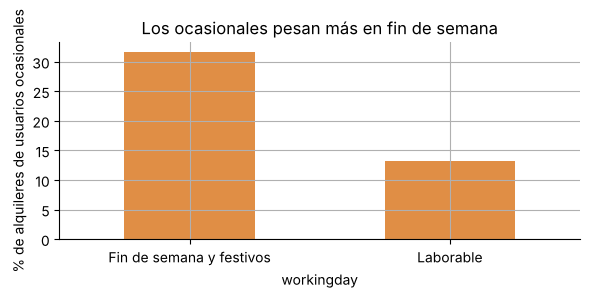

Registrados: 81% de los alquileres · ocasionales: 19%


In [7]:
# Gráfico 4 · Quién alquila (sesgo): usuarios registrados y ocasionales
reparto = horas[["casual", "registered"]].sum() / horas["cnt"].sum()
casual_lab = horas.groupby("workingday")[["casual", "registered"]].sum()
casual_lab = (casual_lab["casual"] / (casual_lab["casual"] + casual_lab["registered"])).rename({0: "Fin de semana y festivos", 1: "Laborable"})
fig, ax = plt.subplots(figsize=(6, 3))
casual_lab.mul(100).plot.bar(ax=ax, color="#e08e45", rot=0)
ax.set_title("Los ocasionales pesan más en fin de semana"); ax.set_ylabel("% de alquileres de usuarios ocasionales")
plt.tight_layout(); plt.show()
print(f"Registrados: {reparto['registered']:.0%} de los alquileres · ocasionales: {reparto['casual']:.0%}")

## 4. Informe de calidad y sesgos

In [8]:
# Informe de calidad y sesgos (cada hallazgo, con la acción tomada)
informe = pd.DataFrame([
    ("Nulos", f"{n_nulos} en todo el fichero", "Ninguna: no hay nulos que rellenar"),
    ("Duplicados", f"{n_duplicados} filas duplicadas y {n_ts_repetidos} horas repetidas", "Ninguna"),
    ("Horas que faltan", f"{n_faltan} de {len(esperadas)} horas no están en el CSV (madrugada, sin alquileres)", "Se crean con cnt = 0 y se marcan (columna `hueco`)"),
    ("Valores imposibles", f"humedad = 0 en {n_hum0} filas de un solo día; viento = 0 en {n_viento0} filas ({n_viento0 / len(horas):.0%})", "El viento 0 se deja (sensor sin viento o sin dato) y se avisa; la humedad 0 se deja y se anota como anomalía de un día"),
    ("Sesgo de muestreo", "Una sola ciudad, un solo operador, 2 años; demanda 2012 un " + f"{crecimiento:.0%} mayor que 2011", "No se promete generalizar a otras ciudades; la tendencia se recoge con retrasos y no con el año"),
    ("Periodos atípicos", f"Huracán Sandy (29-oct-2012): {por_dia[dia_sandy]:.0f} alquileres en el día", "Se mantiene en el test y se mira aparte en la evaluación"),
    ("Desequilibrio", f"solo {int(por_clima.loc[4, 'size'])} horas de tormenta (weathersit = 4)", "No se puede aprender ese caso: se avisa en la model card"),
    ("Fuga de datos potencial", "`casual` y `registered` suman `cnt`: no se conocen antes de la hora; el clima real tampoco se conoce, solo su previsión", "Se excluyen `casual` y `registered`; el clima se usa suponiendo una previsión fiable y se anota como riesgo"),
], columns=["Aspecto", "Hallazgo", "Acción tomada"])
print(informe.to_string(index=False))

                Aspecto                                                                                                                Hallazgo                                                                                                          Acción tomada
                  Nulos                                                                                                    0 en todo el fichero                                                                                     Ninguna: no hay nulos que rellenar
             Duplicados                                                                                  0 filas duplicadas y 0 horas repetidas                                                                                                                Ninguna
       Horas que faltan                                                       165 de 17544 horas no están en el CSV (madrugada, sin alquileres)                                                                    

## 5. Hallazgo que cambia el enfoque

In [9]:
# Hallazgo que cambia el enfoque
print("1. La demanda depende de la hora Y del tipo de día: el modelo necesita `hr` y `workingday`, y un baseline con la media global sería injusto.")
print(f"2. La demanda crece un {crecimiento:.0%} de un año a otro: no se puede barajar ni usar `yr`; se parte por fechas y se usan retrasos (la misma hora de la semana anterior).")
print(f"3. La lluvia recorta la demanda un {cae_lluvia:.0%}: el clima es una variable clave, pero solo se conoce de antemano como previsión (riesgo anotado).")
print("→ Cambio en la ficha: la métrica incluye la hora punta y el clima pasa de «extra» a variable principal, con un modelo sin clima como comparación.")

1. La demanda depende de la hora Y del tipo de día: el modelo necesita `hr` y `workingday`, y un baseline con la media global sería injusto.
2. La demanda crece un 64% de un año a otro: no se puede barajar ni usar `yr`; se parte por fechas y se usan retrasos (la misma hora de la semana anterior).
3. La lluvia recorta la demanda un 45%: el clima es una variable clave, pero solo se conoce de antemano como previsión (riesgo anotado).
→ Cambio en la ficha: la métrica incluye la hora punta y el clima pasa de «extra» a variable principal, con un modelo sin clima como comparación.


## 6. Linaje y huella del dato

In [10]:
# Linaje: huella del conjunto original y del conjunto limpio
import hashlib
huella = hashlib.sha256(open(dato("bicis_horas.csv"), "rb").read()).hexdigest()
print("Huella (sha256) del CSV original:", huella[:16], "…")
print("Linaje: UCI Bike Sharing (hour.csv) → data/bicis_horas.csv (script descargar_datos.py) → serie horaria completa (huecos = 0) → variables → partición por fechas → modelo")

Huella (sha256) del CSV original: b03a2d02e8c10f43 …
Linaje: UCI Bike Sharing (hour.csv) → data/bicis_horas.csv (script descargar_datos.py) → serie horaria completa (huecos = 0) → variables → partición por fechas → modelo


## 7. Cifras para la ficha y el plan de datos

In [11]:
import json, sys, sklearn, matplotlib
cifras = {
    "filas": int(len(horas)), "columnas": int(horas.shape[1] - 1), "dias": int(horas["dteday"].nunique()),
    "periodo": [str(horas["dteday"].min().date()), str(horas["dteday"].max().date())],
    "nulos": n_nulos, "duplicados": n_duplicados, "horas_esperadas": len(esperadas), "faltan": n_faltan,
    "hum0": n_hum0, "viento0": n_viento0, "viento0_pct": round(n_viento0 / len(horas), 3),
    "coherente": coherente, "crecimiento": round(crecimiento, 3), "media_2011": round(float(media_dia[2011])), "media_2012": round(float(media_dia[2012])),
    "sandy": int(por_dia[dia_sandy]), "cae_lluvia": round(cae_lluvia, 3), "horas_tormenta": int(por_clima.loc[4, "size"]),
    "pico_lab": pico_lab, "pico_fin": pico_fin, "pico_lab_bicis": round(float(perfil["Laborable"].max())), "pico_fin_bicis": round(float(perfil["Fin de semana y festivos"].max())),
    "pct_registrados": round(float(reparto["registered"]), 3), "casual_lab": {k: round(float(v), 3) for k, v in casual_lab.items()},
    "huella": huella, "bytes": len(open(dato("bicis_horas.csv"), "rb").read()),
    "versiones": f"Python {sys.version.split()[0]}, numpy {np.__version__}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}",
}
print(json.dumps(cifras, ensure_ascii=False))

{"filas": 17379, "columnas": 17, "dias": 731, "periodo": ["2011-01-01", "2012-12-31"], "nulos": 0, "duplicados": 0, "horas_esperadas": 17544, "faltan": 165, "hum0": 22, "viento0": 2180, "viento0_pct": 0.125, "coherente": true, "crecimiento": 0.644, "media_2011": 3406, "media_2012": 5600, "sandy": 22, "cae_lluvia": 0.454, "horas_tormenta": 3, "pico_lab": 17, "pico_fin": 13, "pico_lab_bicis": 525, "pico_fin_bicis": 373, "pct_registrados": 0.812, "casual_lab": {"Fin de semana y festivos": 0.317, "Laborable": 0.132}, "huella": "b03a2d02e8c10f435c43c7f0b358b7e34a003afea53dbc37f0183f2763295133", "bytes": 1139356, "versiones": "Python 3.13.18, numpy 2.5.3, pandas 2.3.3, matplotlib 3.11.2"}
